In [2]:
with open('../names.txt') as f:
    names = f.read().split('\n')

In [3]:
names[:10]

['emma',
 'olivia',
 'ava',
 'isabella',
 'sophia',
 'charlotte',
 'mia',
 'amelia',
 'harper',
 'evelyn']

In [4]:
print(
    'Longest names:',sorted(names, key = lambda n: -len(n))[0:3],
    '\nShortest names:', sorted(names, key = lambda n: len(n))[0:3]
    )

Longest names: ['muhammadibrahim', 'muhammadmustafa', 'mariaguadalupe'] 
Shortest names: ['an', 'jo', 'bo']


### Making Bigrams

In [5]:
bigrams = {}

for n in names:
    chars = ['<S>'] + list(n) + ['<E>']
    for ch1, ch2 in zip(chars, chars[1:]):
        bi = (ch1, ch2)
        bigrams[bi] = bigrams.get(bi, 0) + 1

In [6]:
print('Most common bigrams:\n', sorted(bigrams.items(), key = lambda t: -t[1])[:5])

Most common bigrams:
 [(('n', '<E>'), 6763), (('a', '<E>'), 6640), (('a', 'n'), 5438), (('<S>', 'a'), 4410), (('e', '<E>'), 3983)]


In [7]:
import torch

In [8]:
N = torch.zeros((28,28), dtype = torch.int32) # Initialise a 28x28 array to store all combinations of lower-case letters + <S> & <E>

In [9]:
# Creating a lookup from string to index to store counts in the torch array

chars = (
            sorted(set(''.join(names)))
            + ['<S>', '<E>']
            )
s2i = {s:i for i,s in enumerate(chars)}
s2i

{'a': 0,
 'b': 1,
 'c': 2,
 'd': 3,
 'e': 4,
 'f': 5,
 'g': 6,
 'h': 7,
 'i': 8,
 'j': 9,
 'k': 10,
 'l': 11,
 'm': 12,
 'n': 13,
 'o': 14,
 'p': 15,
 'q': 16,
 'r': 17,
 's': 18,
 't': 19,
 'u': 20,
 'v': 21,
 'w': 22,
 'x': 23,
 'y': 24,
 'z': 25,
 '<S>': 26,
 '<E>': 27}

In [10]:
for n in names:
    chars = ['<S>'] + list(n) + ['<E>']
    for ch1, ch2 in zip(chars, chars[1:]):
        i, j = s2i[ch1], s2i[ch2]
        N[i,j] += 1

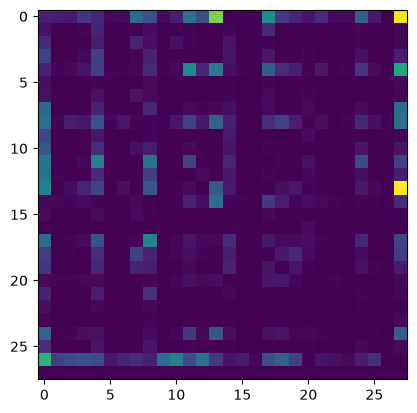

In [11]:
# Crude visualisation of bigram counts

import matplotlib.pyplot as plt

plt.imshow(N)

In [12]:
# Improving the visualisation

i2s = {s2i[s]:s for s in s2i}
i2s

{0: 'a',
 1: 'b',
 2: 'c',
 3: 'd',
 4: 'e',
 5: 'f',
 6: 'g',
 7: 'h',
 8: 'i',
 9: 'j',
 10: 'k',
 11: 'l',
 12: 'm',
 13: 'n',
 14: 'o',
 15: 'p',
 16: 'q',
 17: 'r',
 18: 's',
 19: 't',
 20: 'u',
 21: 'v',
 22: 'w',
 23: 'x',
 24: 'y',
 25: 'z',
 26: '<S>',
 27: '<E>'}

(np.float64(-0.5), np.float64(27.5), np.float64(27.5), np.float64(-0.5))

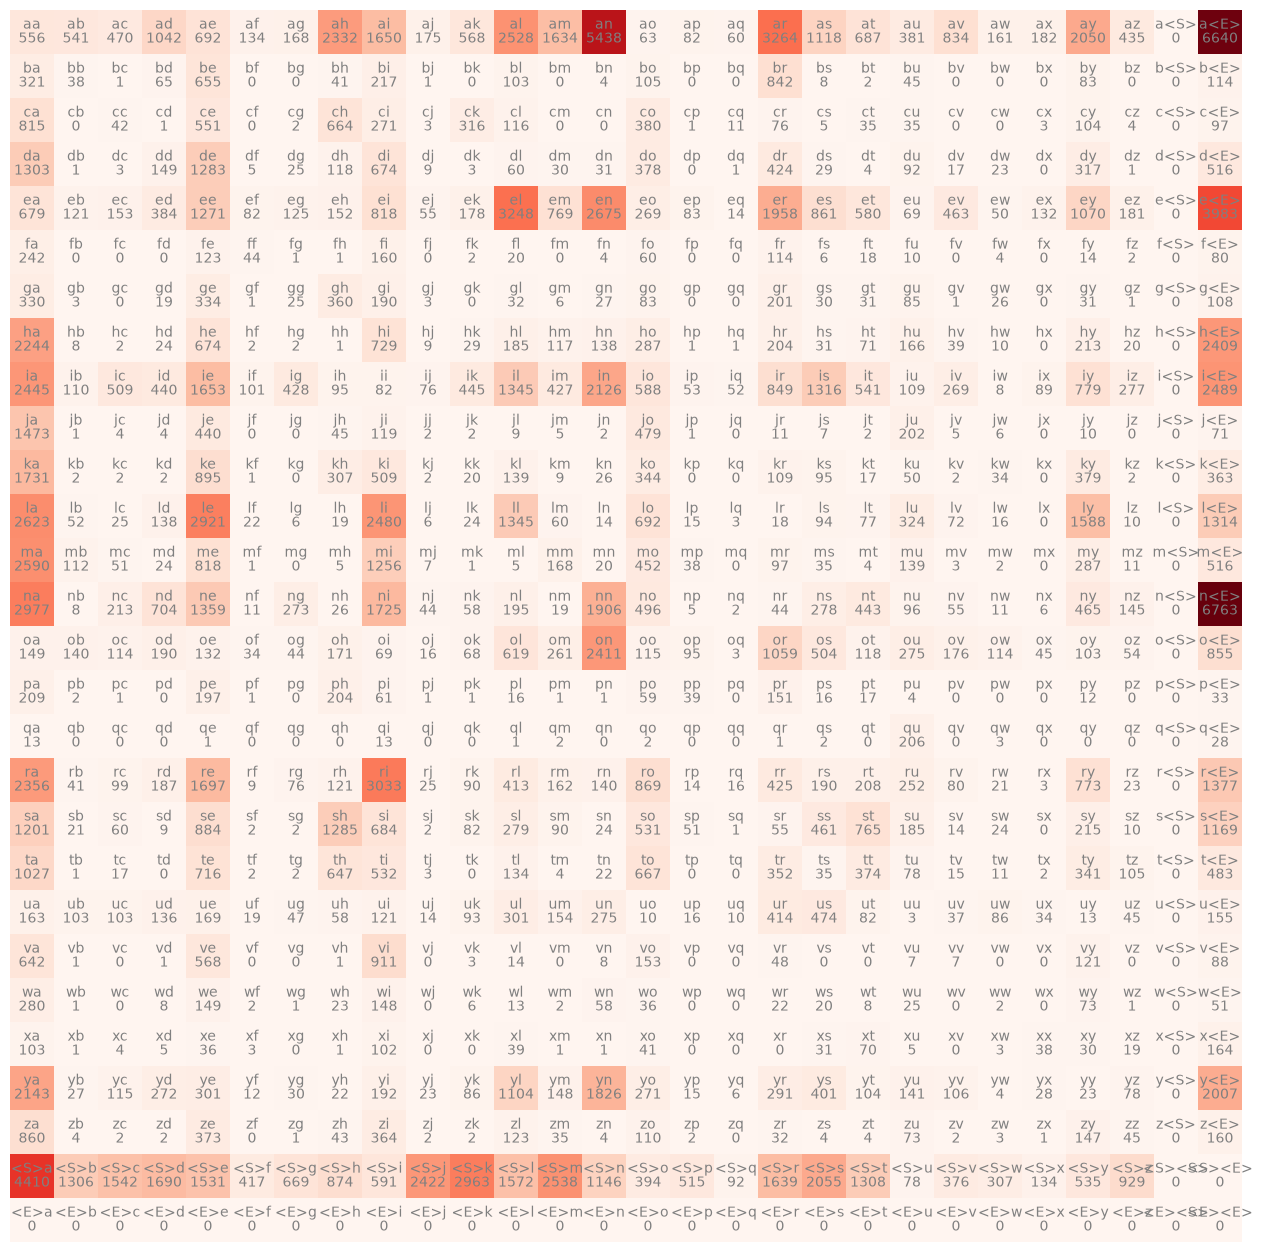

In [13]:
plt.figure(figsize=(16,16))
plt.imshow(N, cmap = 'Reds')
for i in range(28):
    for j in range(28):
        chstr = i2s[i] + i2s[j]
        plt.text(j,i, chstr, ha = 'center', va = 'bottom', color = 'gray')
        plt.text(j,i, N[i,j].item(), ha = 'center', va = 'top', color = 'gray')
plt.axis('off')

### Redoing bigrams with both < S > and < E > as '.'

In [14]:
N = torch.zeros((27,27), dtype = torch.int32)

chars = (
            ['.'] +
            sorted(set(''.join(names)))
            )
s2i = {s:i for i,s in enumerate(chars)}
i2s = {i:s for s,i in s2i.items()}

for n in names:
    chars = ['.'] + list(n) + ['.']
    for ch1, ch2 in zip(chars, chars[1:]):
        i, j = s2i[ch1], s2i[ch2]
        N[i,j] += 1

(np.float64(-0.5), np.float64(26.5), np.float64(26.5), np.float64(-0.5))

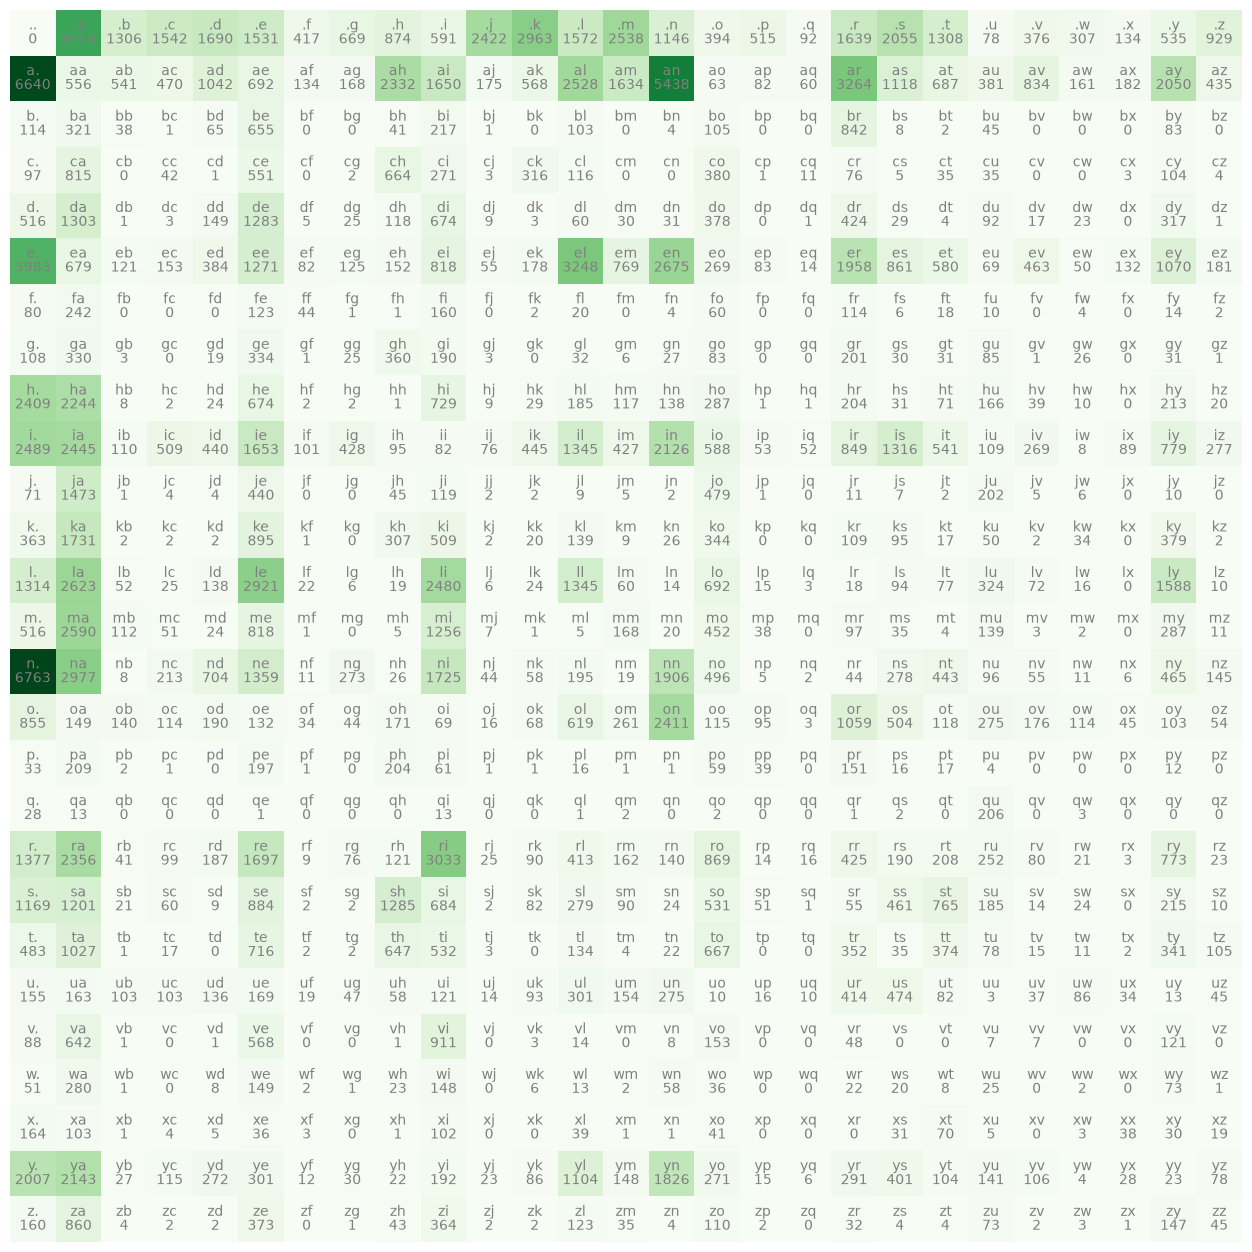

In [15]:
plt.figure(figsize=(16,16))
plt.imshow(N, cmap = 'Greens')
for i in range(27):
    for j in range(27):
        chstr = i2s[i] + i2s[j]
        plt.text(j,i, chstr, ha = 'center', va = 'bottom', color = 'gray')
        plt.text(j,i, N[i,j].item(), ha = 'center', va = 'top', color = 'gray')
plt.axis('off')

### Obtaining probabilities from counts

In [16]:
p = N[0].float() / N[0].sum()
p # Probabilities that a character is the first character in a name

tensor([0.0000, 0.1377, 0.0408, 0.0481, 0.0528, 0.0478, 0.0130, 0.0209, 0.0273,
        0.0184, 0.0756, 0.0925, 0.0491, 0.0792, 0.0358, 0.0123, 0.0161, 0.0029,
        0.0512, 0.0642, 0.0408, 0.0024, 0.0117, 0.0096, 0.0042, 0.0167, 0.0290])

In [17]:
g = torch.Generator().manual_seed(2147483647)
ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
i2s[ix]

'c'

In [18]:
P = N.float() / N.sum(1, keepdim=True)

In [19]:
g = torch.Generator().manual_seed(2147483647)

for _ in range(10):
    ix = 0
    gen = ''
    ch = ''

    while ch != '.':
        # p = N[ix].float() / N[ix].sum()
        # p = torch.ones(27).float()
        ix = torch.multinomial(P[ix], num_samples=1, replacement=True, generator=g).item()
        ch = i2s[ix]
        gen += ch if ch != '.' else ''

    print(gen)

cexze
momasurailezitynn
konimittain
llayn
ka
da
staiyaubrtthrigotai
moliellavo
ke
teda


### Neural Network Approach

In [20]:
# Constructing a cost function for predictions

N_damped = N + 1
P = N_damped.float() / N_damped.sum(1, keepdim=True)

cost = 0
count = 0
for n in names:
    chars = ['.'] + list(n) + ['.']
    for ch1, ch2 in zip(chars, chars[1:]):
        i, j = s2i[ch1], s2i[ch2]
        p = P[i,j]
        loss = -torch.log(p)
        cost+=loss
        count += 1
        # print(f'{ch1}{ch2}\nP(ch2|ch1) = {p*100:.2f}%\n{loss=:.2f}','\n')

print(f'Total Cost: {cost}\nAvg Cost: {cost/count:.2f}')

Total Cost: 559951.5625
Avg Cost: 2.45


In [21]:
# Creating input and label tensors

x, y = [], []

for n in names:
    chars = ['.'] + list(n) + ['.']
    for ch1, ch2 in zip(chars, chars[1:]):
        i, j = s2i[ch1], s2i[ch2]
        x.append(i)
        y.append(j)

x, y = torch.tensor(x), torch.tensor(y)

In [22]:
# One-hot encoding inputs and labels

from torch.nn.functional import one_hot

x_enc = one_hot(x, num_classes=27).float()
y_enc = one_hot(y, num_classes=27).float()

### Manual backpropagation

In [149]:
g = torch.Generator().manual_seed(2147483647)
W = torch.randn((27,27), requires_grad=True, generator=g)

logits = (x_enc @ W).exp()
probs = logits / logits.sum(1, keepdim=True)
loss = -probs[torch.arange(0,5),y[:5]].log().mean()

In [150]:
W.grad = None
loss.backward()

In [ ]:
# GD on just first 5 bigrams

epochs = 0
req_loss = 1e-6
lr = 0.05

while epochs <= 5000 and loss > req_loss:
    logits = (x_enc @ W).exp()
    probs = logits / logits.sum(1, keepdim=True)
    loss = -probs[torch.arange(0,5),y[:5]].log().mean()

    W.grad = None
    loss.backward()

    W.data -= lr * W.grad

    if epochs % 500 == 0:
        print(f'Epoch: {epochs}\nLoss: {loss}\n')

    epochs += 1

Epoch: 0
Loss: 0.340010404586792

Epoch: 500
Loss: 0.3247528374195099

Epoch: 1000
Loss: 0.3153855502605438

Epoch: 1500
Loss: 0.30906933546066284

Epoch: 2000
Loss: 0.30453047156333923

Epoch: 2500
Loss: 0.30111488699913025

Epoch: 3000
Loss: 0.2984536588191986

Epoch: 3500
Loss: 0.2963225841522217

Epoch: 4000
Loss: 0.29457828402519226

Epoch: 4500
Loss: 0.2931247651576996

Epoch: 5000
Loss: 0.2918950915336609



In [152]:
# GD on all bigrams

epochs = 0
req_loss = 1
lr = 1
# W.grad = None

while epochs <= 10000 and loss > req_loss:
    logits = (x_enc @ W).exp()
    probs = logits / logits.sum(1, keepdim=True)
    loss = -probs[torch.arange(x.nelement()),y].log().mean()

    W.grad = None
    loss.backward()

    W.data -= lr * W.grad

    if epochs % 500 == 0:
        print(f'Epoch: {epochs}\nLoss: {loss}\n')

    epochs += 1

Epoch: 0
Loss: 3.6548268795013428

Epoch: 500
Loss: 2.655723810195923

Epoch: 1000
Loss: 2.5158028602600098

Epoch: 1500
Loss: 2.4550299644470215

Epoch: 2000
Loss: 2.454439640045166

Epoch: 2500
Loss: 2.4543049335479736

Epoch: 3000
Loss: 2.454242467880249

Epoch: 3500
Loss: 2.4542086124420166

Epoch: 4000
Loss: 2.454188346862793

Epoch: 4500
Loss: 2.4541757106781006

Epoch: 5000
Loss: 2.454166889190674

Epoch: 5500
Loss: 2.454160690307617

Epoch: 6000
Loss: 2.454155921936035

Epoch: 6500
Loss: 2.4541523456573486

Epoch: 7000
Loss: 2.4541499614715576

Epoch: 7500
Loss: 2.4541478157043457

Epoch: 8000
Loss: 2.454146146774292

Epoch: 8500
Loss: 2.4541444778442383

Epoch: 9000
Loss: 2.4541432857513428

Epoch: 9500
Loss: 2.4541425704956055

Epoch: 10000
Loss: 2.454141855239868



In [176]:
# Neural net predictor

g = torch.Generator().manual_seed(2147483647)

for _ in range(10):
    ix = 0
    gen = ''
    ch = ''

    while ch != '.':
        x_enc = one_hot(torch.tensor(ix), num_classes=27).float()
        logits = x_enc @ W
        counts = logits.exp()

        p = counts / counts.sum()

        ix = torch.multinomial(P[ix], num_samples=1, replacement=True, generator=g).item()
        ch = i2s[ix]
        gen += ch if ch != '.' else ''

    print(gen)

cexze
momasurailezitynn
konimittain
llayn
ka
da
staiyaubrtthrigotai
moliellavo
ke
teda
